# Visualize annual index levels

Load saved index-level confidence intervals and visualize annual spatial means, their spatial CI bands, and correlogram diagnostics. These cells do not recompute the statistical estimates.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from index_ci import IndexAnalysisConfig
from index_ci.plotting import (
    plot_index_correlogram,
    plot_index_heatmap,
    plot_index_n_eff,
    plot_index_timeseries,
    save_figure,
)
from plot_style import add_shared_legend, finish_panel_grid, month_name

ROOT = Path.cwd().parent
assert (ROOT / 'pyproject.toml').exists(), 'Run notebooks from the notebooks/ folder'
config = IndexAnalysisConfig.from_yaml(
    ROOT / 'configs' / 'index_ci.yaml', project_root=ROOT
)

## Load saved outputs

In [2]:
PLOT_INDEX = 'NDVI'
if PLOT_INDEX not in config.index_bands:
    raise ValueError(f'Index is not configured: {PLOT_INDEX}')
RESULTS_DIR = config.output_dir / PLOT_INDEX
PLOT_DIR = RESULTS_DIR / 'plots'
results = pd.read_csv(RESULTS_DIR / 'results.csv')
correlograms = pd.read_csv(RESULTS_DIR / 'correlograms.csv')
primary = results.loc[results['is_primary_tau']].copy()
wadi = primary.loc[primary['study_area'] == 'WadiGaza'].copy()
study_areas = sorted(primary['study_area'].astype(str).unique())
if wadi.empty:
    raise ValueError('No WadiGaza results found')
print(
    f'{len(primary)} primary results overall; {len(wadi)} for WadiGaza; '
    f'{len(correlograms)} correlogram rows'
)

196 primary results overall; 28 for WadiGaza; 14672 correlogram rows


## Wadi Gaza annual trajectories

Each line is a study month; translucent bands are spatially adjusted 95% CIs.

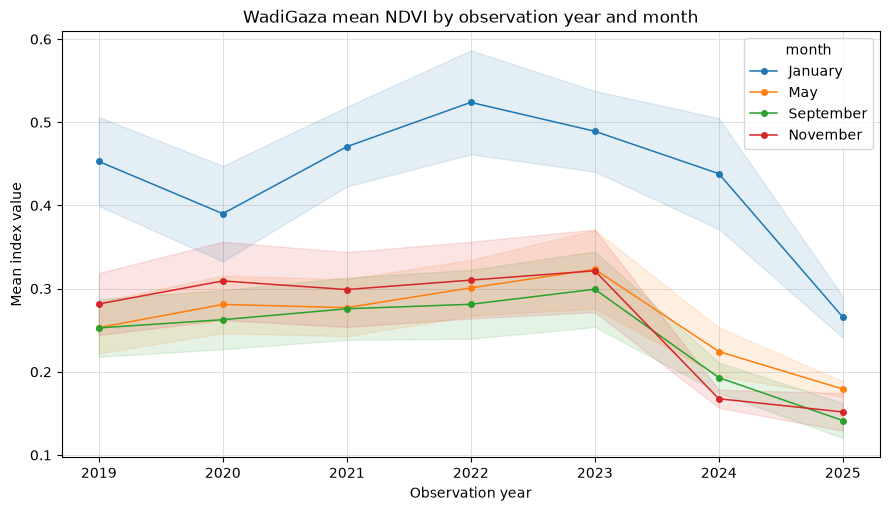

In [3]:
fig, ax = plot_index_timeseries(wadi, group_by='month', show_ci_for='all')
ax.set_title(f'WadiGaza mean {PLOT_INDEX} by observation year and month')
save_figure(fig, PLOT_DIR / 'WadiGaza_mean_index_timeseries.png')
plt.show()

## Wadi Gaza compared with other study areas

Wadi Gaza is emphasized with a solid line and CI band. Other sites are dotted and shown as context without CI bands. One shared legend sits below the panels.

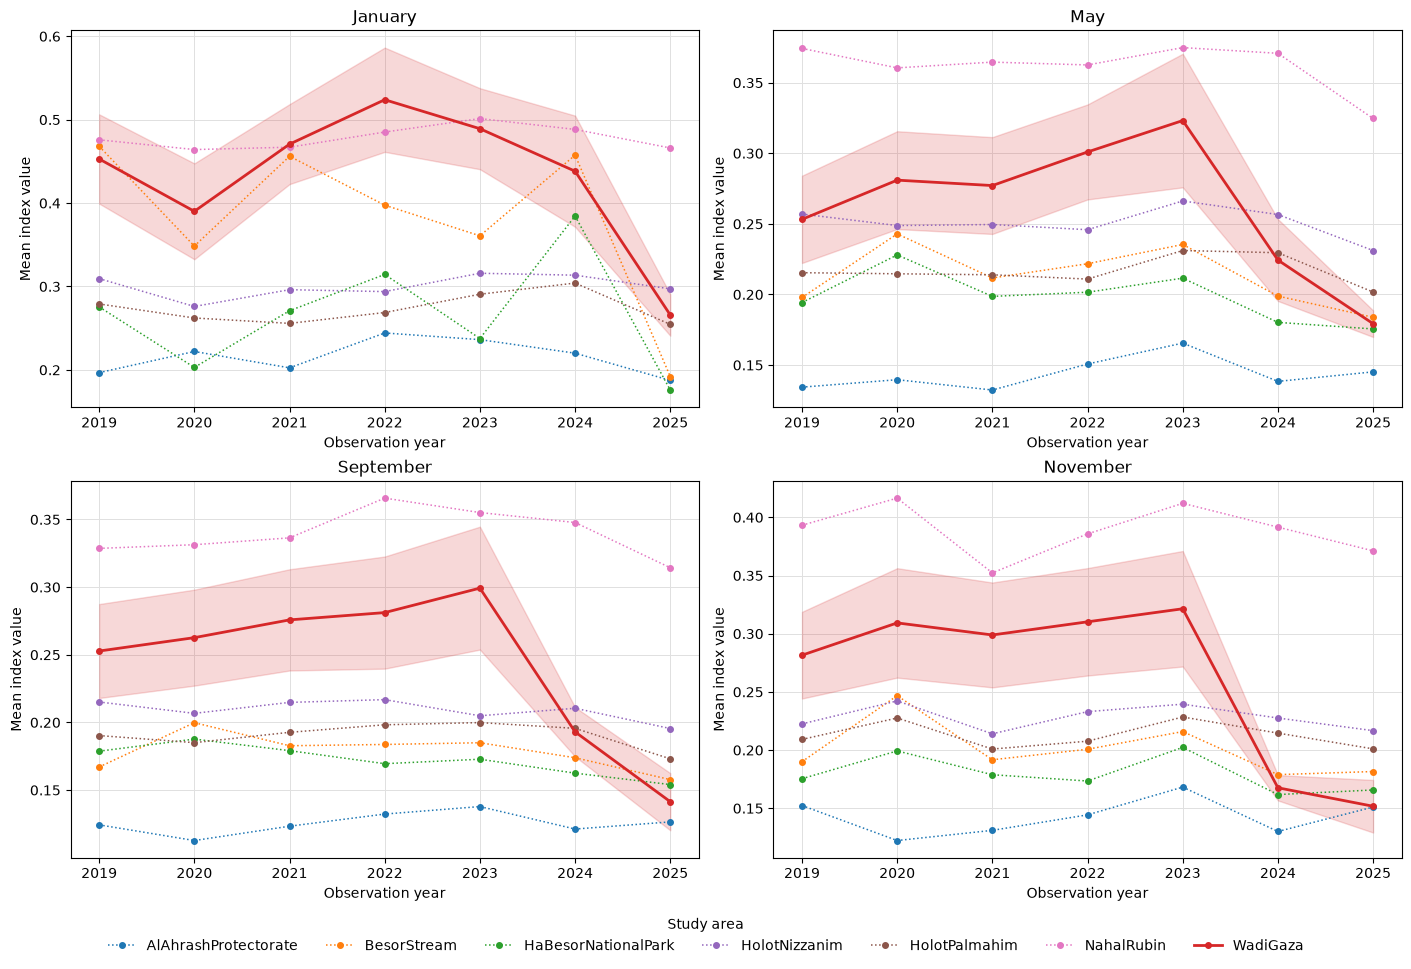

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
for ax, month in zip(axes.flat, config.months):
    plot_index_timeseries(
        primary,
        group_by='study_area',
        filters={'month': month},
        show_ci_for=('WadiGaza',),
        highlight='WadiGaza',
        ax=ax,
    )
    ax.set_title(month_name(month))
add_shared_legend(fig, axes, title='Study area', ncol=7)
save_figure(fig, PLOT_DIR / 'WadiGaza_vs_study_areas_index_timeseries.png')
plt.show()

## Wadi Gaza compared with other study areas, relative to a base year

Each site's annual mean is expressed as percent change from its own base-year mean, so sites with different absolute index levels can be compared on a common scale. Bands rescale the Wadi Gaza spatial 95% CI by the fixed base-year mean; they do not include uncertainty in the base-year value itself.

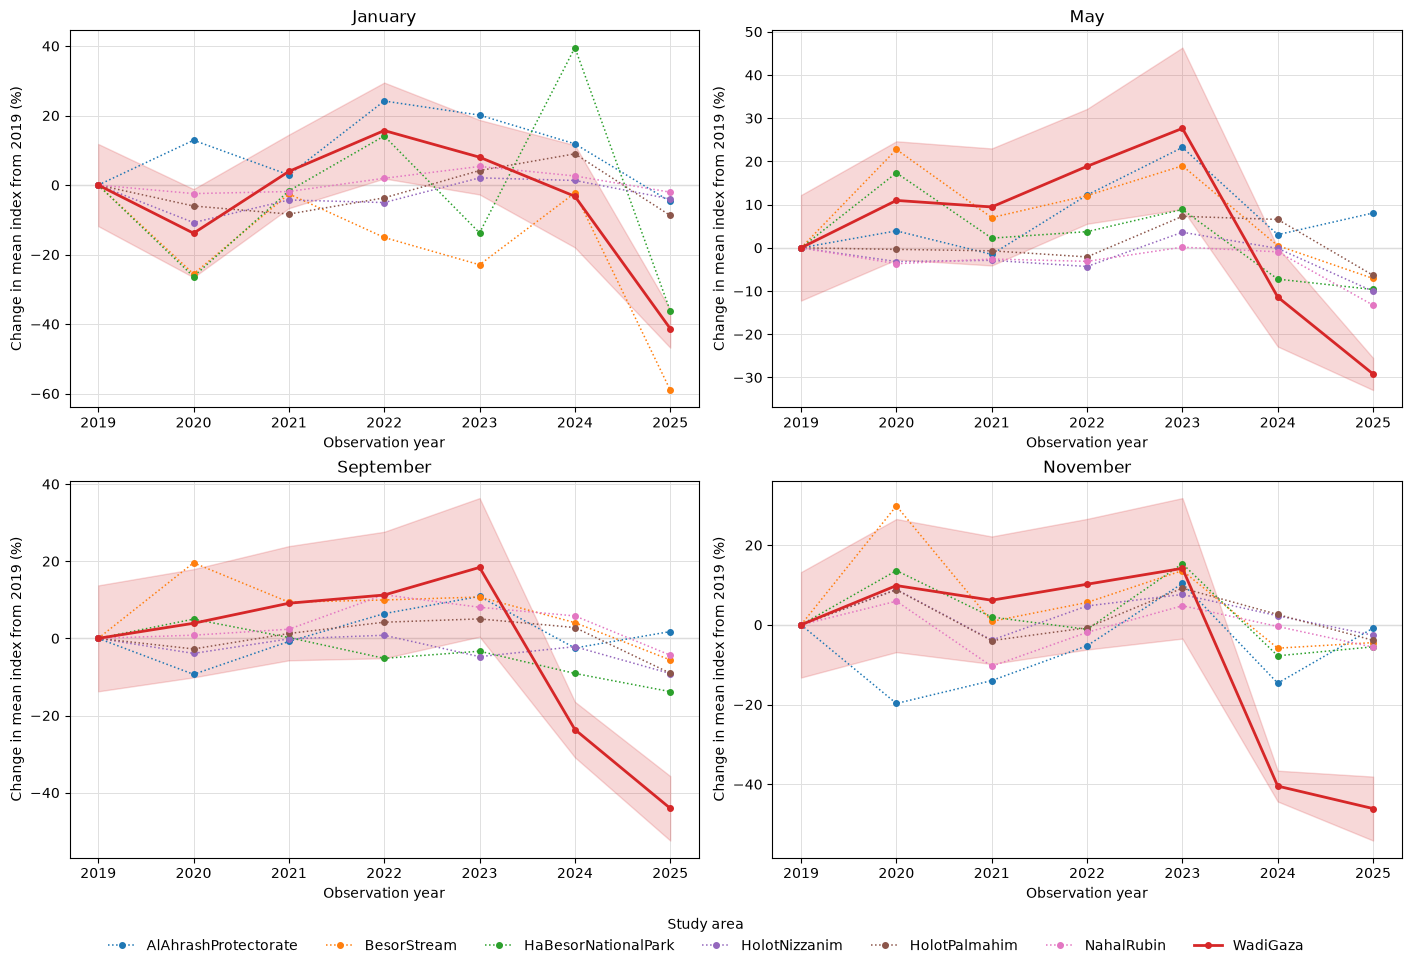

In [5]:
BASE_YEAR = 2019
fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
for ax, month in zip(axes.flat, config.months):
    plot_index_timeseries(
        primary,
        group_by='study_area',
        filters={'month': month},
        show_ci_for=('WadiGaza',),
        highlight='WadiGaza',
        ax=ax,
        base_year=BASE_YEAR,
    )
    ax.set_title(month_name(month))
add_shared_legend(fig, axes, title='Study area', ncol=7)
save_figure(fig, PLOT_DIR / f'WadiGaza_vs_study_areas_index_change_from_{BASE_YEAR}.png')
plt.show()

## Site-by-year heatmaps by month

A shared color scale, shown by one colorbar, makes the four month panels directly comparable. Site and year labels appear once, on the left column and bottom row.

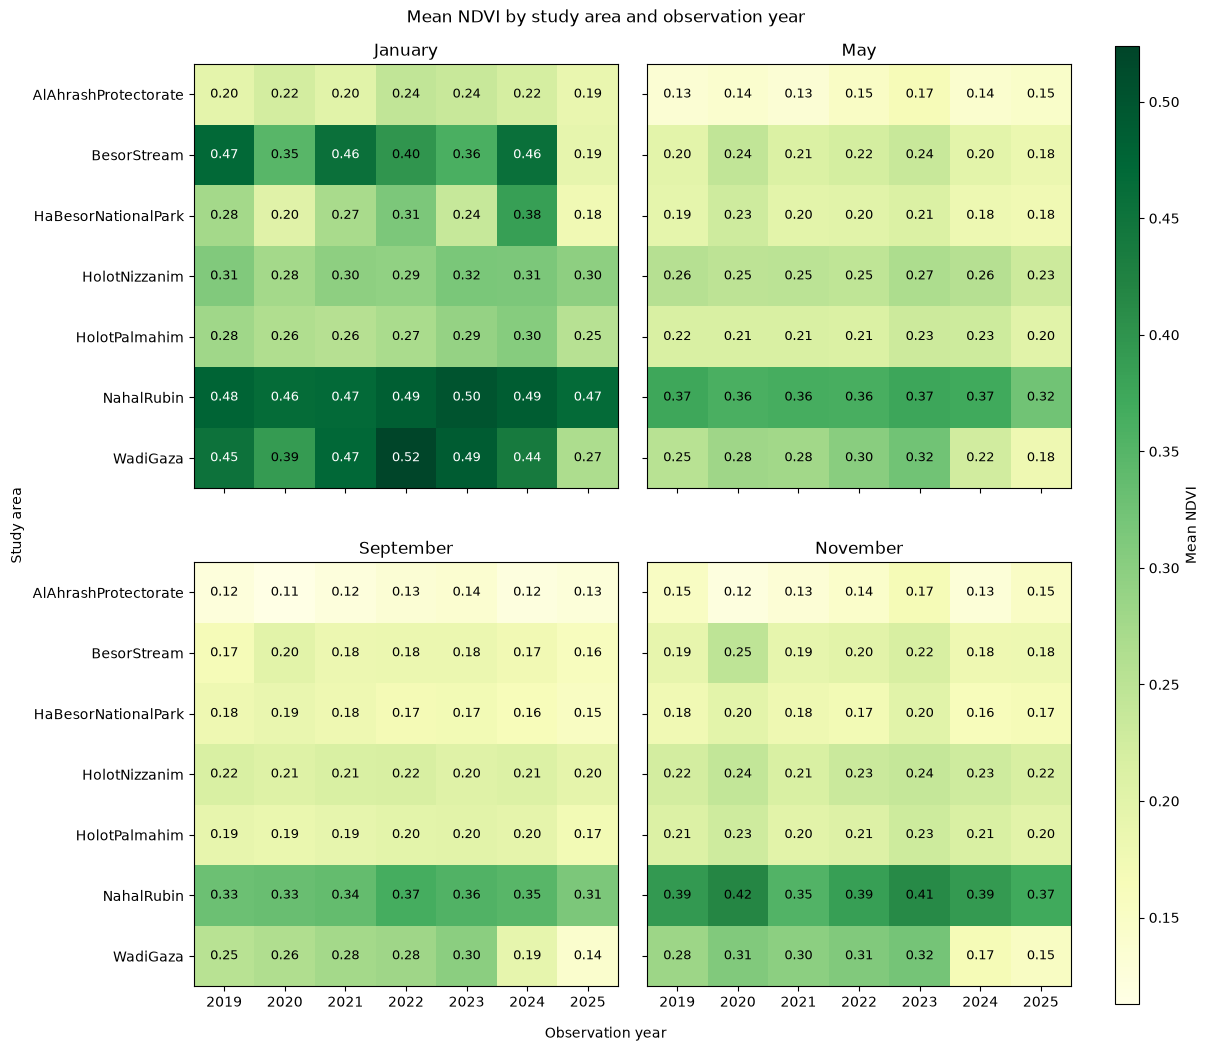

In [6]:
vmin = float(primary['mean_index'].min())
vmax = float(primary['mean_index'].max())
fig, axes = plt.subplots(2, 2, figsize=(12, 10.4), constrained_layout=True)
for ax, month in zip(axes.flat, config.months):
    plot_index_heatmap(
        primary, month, ax=ax, sites=study_areas, vmin=vmin, vmax=vmax, colorbar=False,
    )
    ax.set_title(month_name(month))
finish_panel_grid(
    fig, axes, label=f'Mean {PLOT_INDEX}',
    title=f'Mean {PLOT_INDEX} by study area and observation year',
)
save_figure(fig, PLOT_DIR / 'study_area_mean_index_heatmaps.png')
plt.show()

## Effective sample size over time

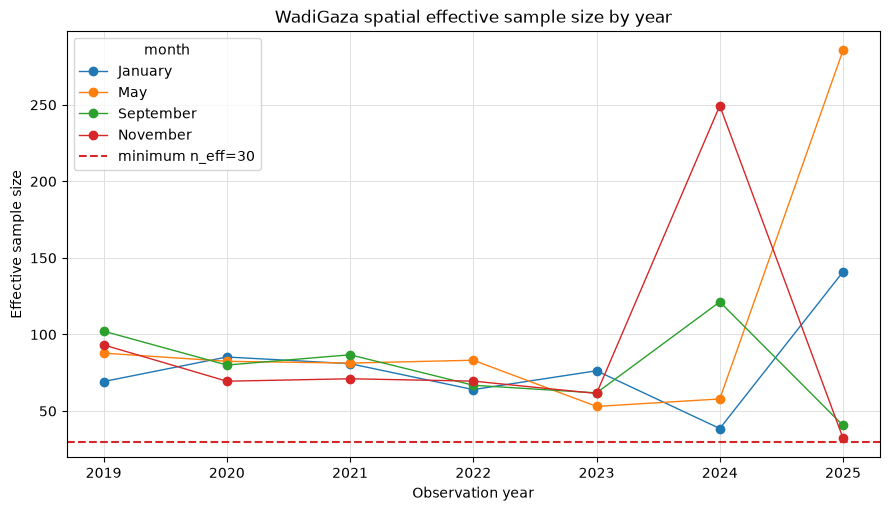

In [7]:
fig, ax = plot_index_n_eff(wadi, group_by='month', min_n_eff=config.min_n_eff)
ax.set_title('WadiGaza spatial effective sample size by year')
save_figure(fig, PLOT_DIR / 'WadiGaza_index_effective_sample_size.png')
plt.show()

## Wadi Gaza correlograms by observation year

The panels show the primary range threshold and the sensitivity thresholds for a selected month.

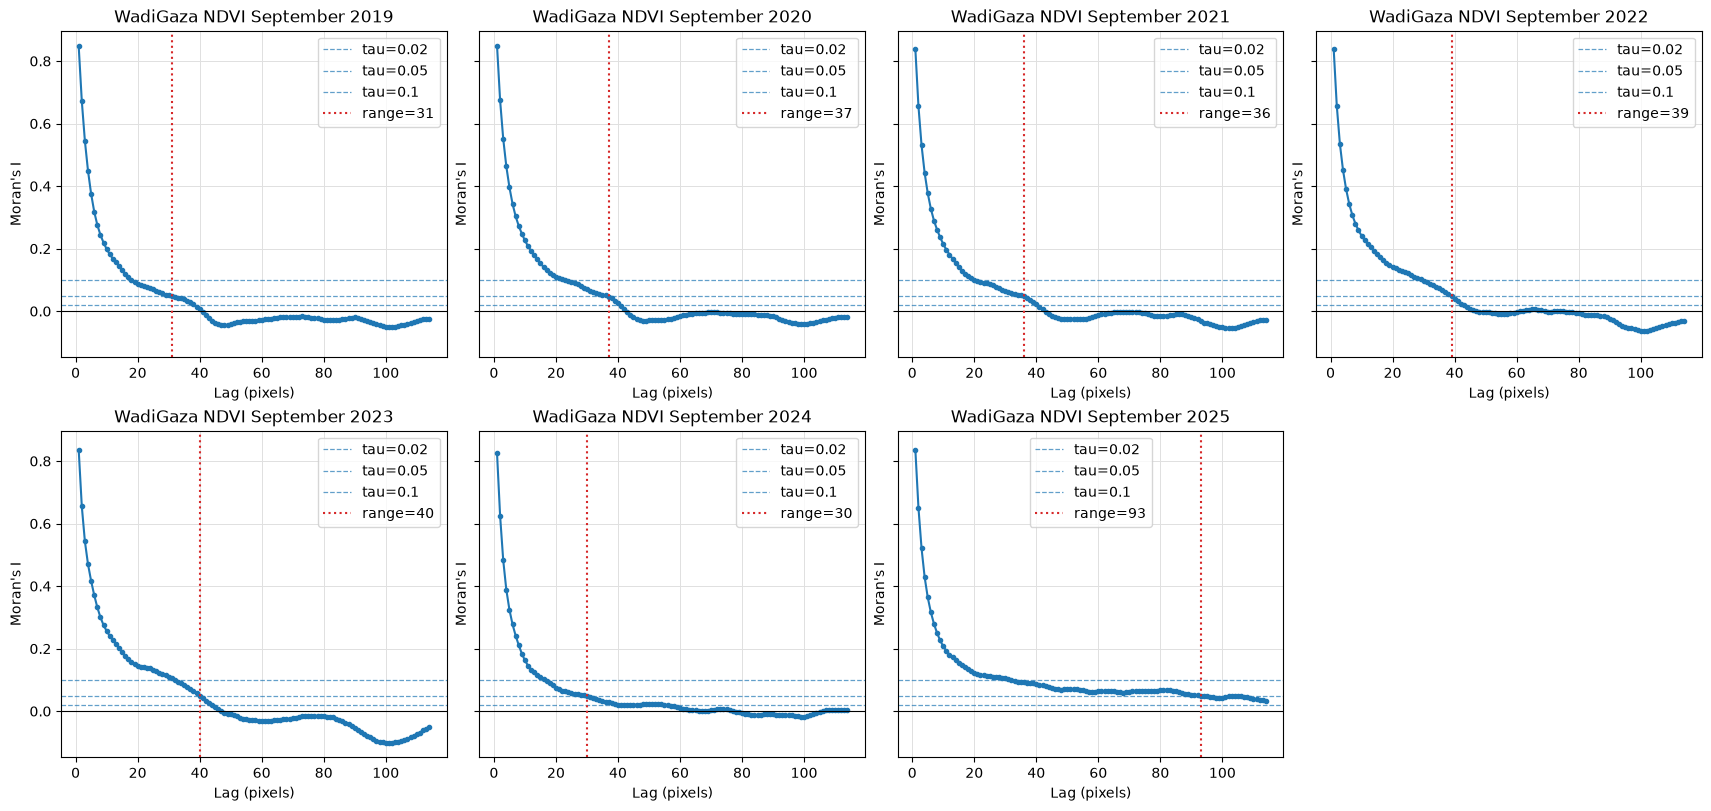

In [8]:
PLOT_MONTH = '09'
years = sorted(primary.loc[
    (primary['study_area'] == 'WadiGaza') & (primary['month'].astype(str).str.zfill(2) == PLOT_MONTH),
    'year',
].astype(int).unique())
fig, axes = plt.subplots(2, 4, figsize=(17, 8), sharey=True, constrained_layout=True)
for ax, year in zip(axes.flat, years):
    plot_index_correlogram(
        correlograms,
        results,
        {'study_area': 'WadiGaza', 'index': PLOT_INDEX, 'month': PLOT_MONTH, 'year': year},
        ax=ax,
    )
for ax in axes.flat[len(years):]:
    ax.set_visible(False)
save_figure(fig, PLOT_DIR / f'WadiGaza_{PLOT_MONTH}_index_correlograms_by_year.png')
plt.show()